In [2]:
import warnings
warnings.simplefilter(action='ignore')
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm

# TAMA

### Reduce sqanti output

In [10]:
sqanti = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/at9900_liftoff_sqanti/at9900-tama-vs-liftoff_classification.txt", sep="\t")
sub = sqanti[["isoform","exons","length","structural_category","associated_gene","associated_transcript","subcategory","ORF_seq"]]
sub["gene"] = sub["isoform"].str.split(".").str[0]

### Read Support

In [11]:
reads = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/at9900.collapsed.tama.v2_read_support.txt", sep="\t")
r_sub = reads[["merge_trans_id","trans_read_count","gene_read_count"]]
r_sub.columns = ["isoform", "isoform_reads", "gene_reads"]

### Sqanti + Read Support

In [12]:
merged_all = pd.merge(left=sub, right=r_sub, how='left', left_on='isoform', right_on='isoform')

In [13]:
merged_all["gene_reads"].head()

0     2
1     2
2     2
3     2
4    93
Name: gene_reads, dtype: int64

In [14]:
merged_all.head()
# subset via isoform and/or gene read cov >1 #

,isoform,exons,length,structural_category,associated_gene,associated_transcript,subcategory,ORF_seq,gene,isoform_reads,gene_reads
0,G1.1,6,1542,full-splice_match,AT1G01010,AT1G01010.1,alternative_3end,MEDQVGFGFRPNDEELVGHYLRNKIEGNTSRDVEVAISEVNICSYD...,G1,1,2
1,G1.2,6,1685,full-splice_match,AT1G01010,AT1G01010.1,reference_match,MEDQVGFGFRPNDEELVGHYLRNKIEGNTSRDVEVAISEVNICSYD...,G1,1,2
2,G10.1,5,1939,full-splice_match,AT1G01110,AT1G01110.2,alternative_5end,MGKKNGSSSWLTAVKRAFRSPTKKDHSNDVEEDEEKKREKRRWFRK...,G10,1,2
3,G10.2,5,1909,novel_not_in_catalog,AT1G01110,novel,at_least_one_novel_splicesite,MGKKNGSSSWLTAVKRAFRSPTKKDHSNDVEEDEEKREKRRWFRKP...,G10,1,2
4,G100.1,8,1229,full-splice_match,AT1G02280,AT1G02280.1,alternative_3end,MGSLVREWVGFQQFPAATQEKLIEFFGKLKQKDMNSMTVLVLGKGG...,G100,1,93


# Ref Genes

In [7]:
busco = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/analysis/sqanti/ref_genes/busco_Araport11_20221221.txt", header=None)
house = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/analysis/sqanti/ref_genes/arat_housekeeping.txt", header=None)
nlr = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/analysis/sqanti/ref_genes/nlrs_in_orthogroups_20221221.txt", header=None)

In [8]:
busco["type"] = "busco"
house["type"] = "housekeeping"
nlr["type"] = "nlr"
gene_type = pd.concat([busco,house,nlr])
gene_type.columns = ["ref_isoform","type"]
gene_type = gene_type.groupby("ref_isoform")["type"].apply(', '.join).reset_index()

In [9]:
gene_type["ref_gene"] = gene_type["ref_isoform"].str.split(".").str[0]
gene_type.loc[gene_type["type"] == "busco, nlr"] = "nlr"
gene_type.loc[gene_type["type"] == "housekeeping, nlr"] = "nlr"
gene_type.loc[gene_type["type"] == "busco, housekeeping"] = "housekeeping"
print(gene_type["type"].value_counts())

busco           4483
housekeeping     704
nlr              252
Name: type, dtype: int64


### RELATE VIA ISOFORM, NOT GENE HERE

In [10]:
iso_ref = pd.merge(left=merged_all, right=gene_type, how='left', left_on='associated_transcript', right_on='ref_isoform')
print(iso_ref["type"].value_counts())
iso_nlr = iso_ref.loc[iso_ref["type"] == "nlr"]
iso_busco = iso_ref.loc[iso_ref["type"] == "busco"]
iso_house = iso_ref.loc[iso_ref["type"] == "housekeeping"]
iso_all = pd.concat([iso_nlr,iso_busco,iso_house])

busco           31485
housekeeping     2149
nlr               744
Name: type, dtype: int64


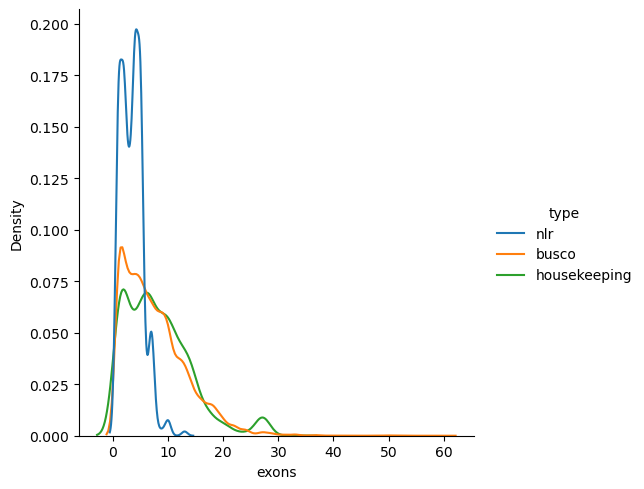

In [11]:
sns.displot(iso_all, x="exons", hue = "type", kind="kde",common_norm=False)

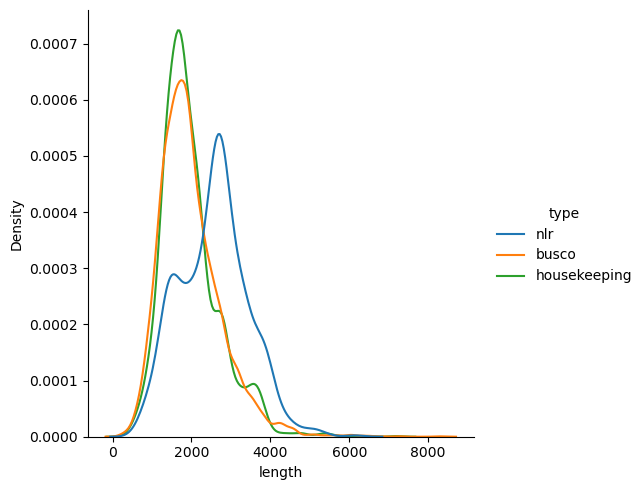

In [12]:
sns.displot(iso_all, x="length", hue = "type", kind="kde",common_norm=False)

([0, 1, 2, 3, 4, 5, 6, 7, 8],
 [Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, '')])

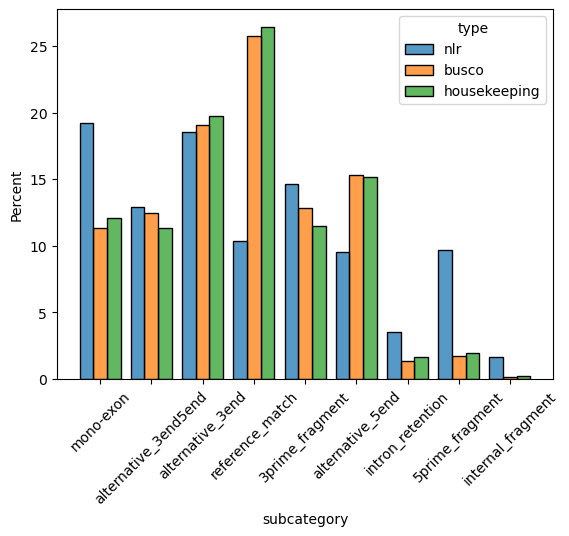

In [13]:
sns.histplot(iso_all, x="subcategory", hue = "type", multiple= "dodge", stat="percent", common_norm=False, shrink = 0.8)
plt.xticks(rotation=45)

### RELATE VIA GENE, NOT ISOFORM HERE

In [14]:
gene_ref = pd.merge(left=merged_all, right=gene_type, how='left', left_on='associated_gene', right_on='ref_gene')
print(gene_ref["type"].value_counts())
gene_nlr = gene_ref.loc[gene_ref["type"] == "nlr"]
gene_busco = gene_ref.loc[gene_ref["type"] == "busco"]
gene_house = gene_ref.loc[gene_ref["type"] == "housekeeping"]
gene_all = pd.concat([gene_nlr,gene_busco,gene_house])

busco           41710
housekeeping     4253
nlr              1377
Name: type, dtype: int64


In [15]:
gene_ref.head()

,isoform,exons,length,structural_category,associated_gene,associated_transcript,subcategory,ORF_seq,gene,isoform_reads,gene_reads,ref_isoform,type,ref_gene
0,G1.1,6,1542,full-splice_match,AT1G01010,AT1G01010.1,alternative_3end,MEDQVGFGFRPNDEELVGHYLRNKIEGNTSRDVEVAISEVNICSYD...,G1,1,2,NaN,NaN,NaN
1,G1.2,6,1685,full-splice_match,AT1G01010,AT1G01010.1,reference_match,MEDQVGFGFRPNDEELVGHYLRNKIEGNTSRDVEVAISEVNICSYD...,G1,1,2,NaN,NaN,NaN
2,G10.1,5,1939,full-splice_match,AT1G01110,AT1G01110.2,alternative_5end,MGKKNGSSSWLTAVKRAFRSPTKKDHSNDVEEDEEKKREKRRWFRK...,G10,1,2,NaN,NaN,NaN
3,G10.2,5,1909,novel_not_in_catalog,AT1G01110,novel,at_least_one_novel_splicesite,MGKKNGSSSWLTAVKRAFRSPTKKDHSNDVEEDEEKREKRRWFRKP...,G10,1,2,NaN,NaN,NaN
4,G100.1,8,1229,full-splice_match,AT1G02280,AT1G02280.1,alternative_3end,MGSLVREWVGFQQFPAATQEKLIEFFGKLKQKDMNSMTVLVLGKGG...,G100,1,93,NaN,NaN,NaN


In [16]:
gene_nlr["structural_category"].value_counts()

full-splice_match          524
novel_not_in_catalog       368
incomplete-splice_match    285
novel_in_catalog           140
genic                       60
Name: structural_category, dtype: int64

In [17]:
gene_nlr["subcategory"].value_counts()

intron_retention                    288
at_least_one_novel_splicesite       221
mono-exon                           218
alternative_3end                    140
3prime_fragment                     139
alternative_3end5end                101
reference_match                      81
5prime_fragment                      74
alternative_5end                     72
mono-exon_by_intron_retention        16
internal_fragment                    13
multi-exon                            8
combination_of_known_splicesites      6
Name: subcategory, dtype: int64

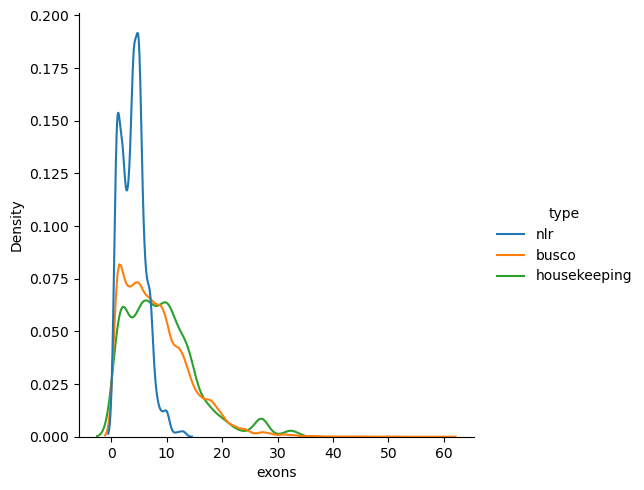

In [18]:
#sns.histplot(gene_all, x="exons", hue = "type", multiple= "dodge", stat="percent", common_norm=False, shrink = 1.4)
sns.displot(gene_all, x="exons", hue = "type", kind="kde",common_norm=False)
plt.savefig("tama_liftoff_sqanti_exons.png", bbox_inches='tight')

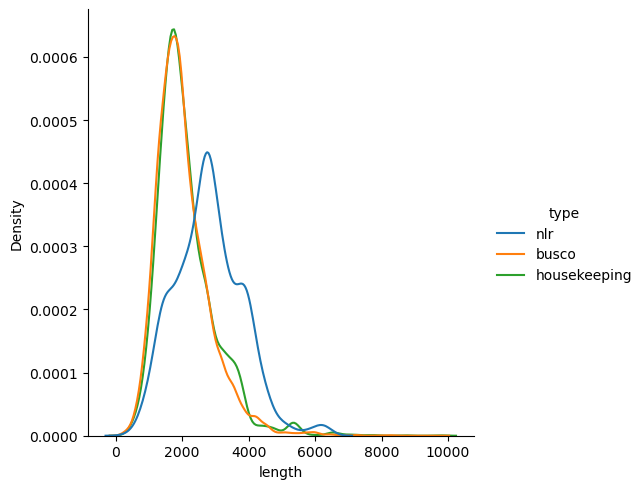

In [19]:
sns.displot(gene_all, x="length", hue = "type", kind="kde",common_norm=False)
plt.savefig("tama_liftoff_sqanti_length.png", bbox_inches='tight')

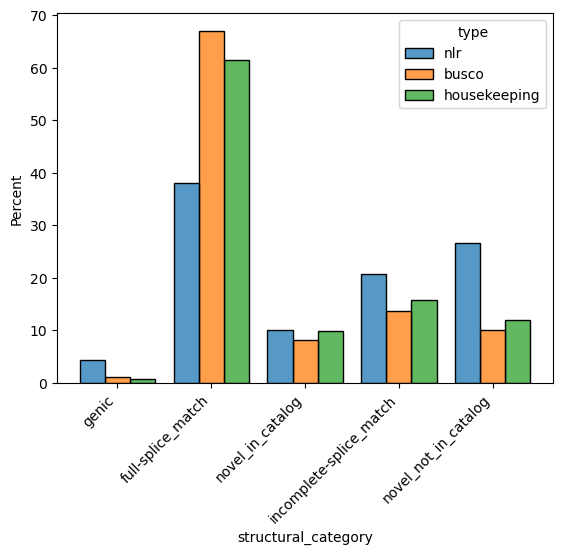

In [20]:
sns.histplot(gene_all, x="structural_category", hue = "type", multiple= "dodge", stat="percent", common_norm=False, shrink = 0.8)
plt.xticks(rotation=45, horizontalalignment='right')
plt.savefig("tama_liftoff_sqanti_category.png", bbox_inches='tight')

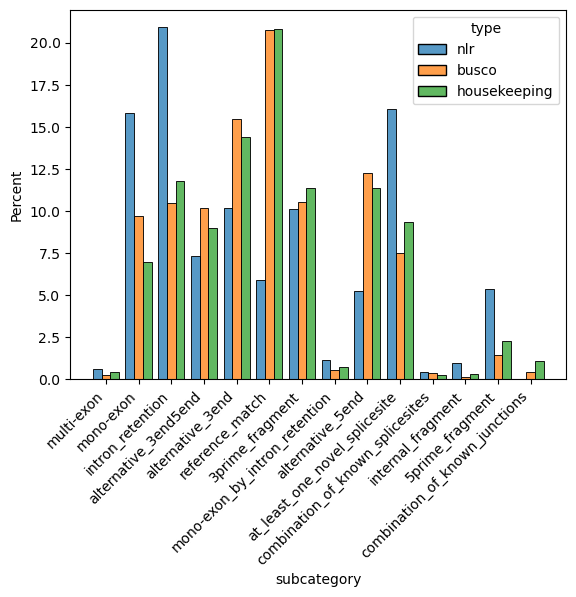

In [21]:
sns.histplot(gene_all, x="subcategory", hue = "type", multiple= "dodge", stat="percent", common_norm=False, shrink = 0.8)
plt.xticks(rotation=45, horizontalalignment='right')
plt.savefig("tama_liftoff_sqanti_subcategory.png", bbox_inches='tight')
##### only show the isoforms with read support >2 #####
#### also do: genes >1 read ####

# Include all genes as background (incl. RefSets)

In [22]:
tt = merged_all.copy()
tt["ref_isoform"] = "None"
tt["type"] = "all"
tt["ref_gene"] = "None"
tt.head()
acc_all = pd.concat([gene_all,tt], ignore_index=True)

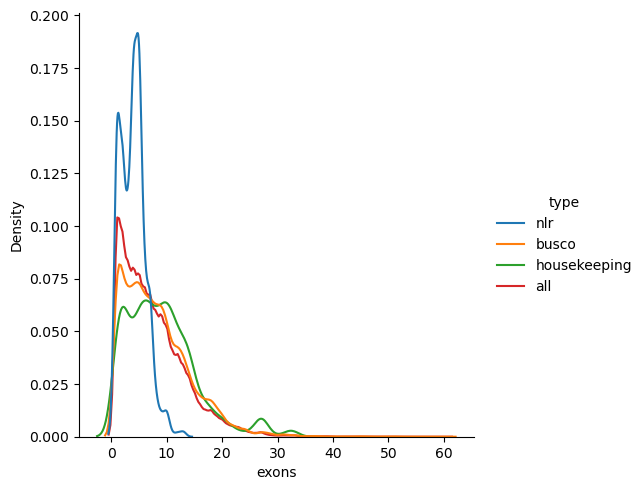

In [23]:
sns.displot(acc_all, x="exons", hue = "type", kind="kde",common_norm=False)
plt.savefig("tama_liftoff_sqanti_exons_all.png", bbox_inches='tight')

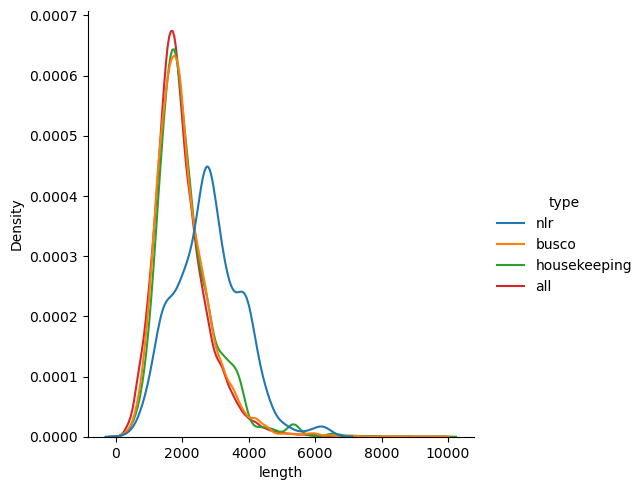

In [24]:
sns.displot(acc_all, x="length", hue = "type", kind="kde",common_norm=False)
plt.savefig("tama_liftoff_sqanti_length_all.png", bbox_inches='tight')

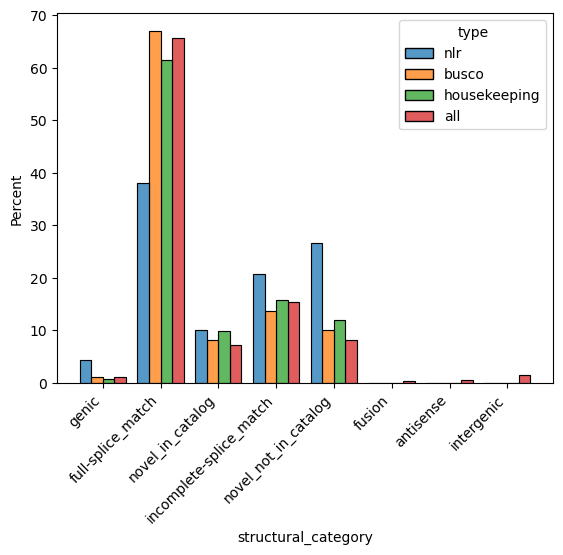

In [25]:
sns.histplot(acc_all, x="structural_category", hue = "type", multiple= "dodge", stat="percent", common_norm=False, shrink = 0.8)
plt.xticks(rotation=45, horizontalalignment='right')
plt.savefig("tama_liftoff_sqanti_category_all.png", bbox_inches='tight')

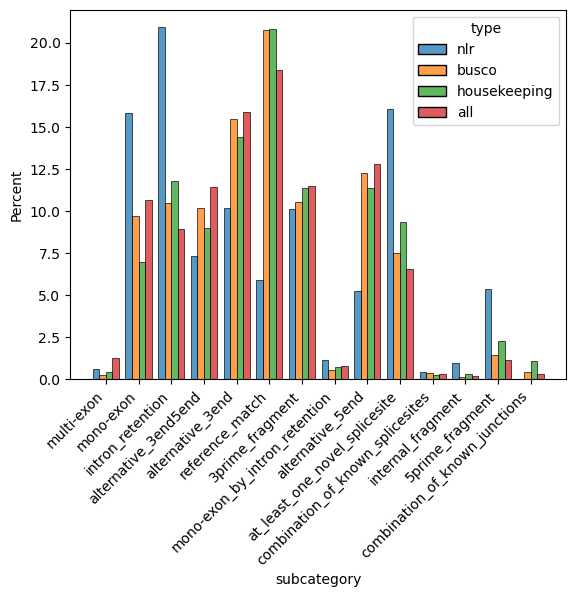

In [26]:
sns.histplot(acc_all, x="subcategory", hue = "type", multiple= "dodge", stat="percent", common_norm=False, shrink = 0.8)
plt.xticks(rotation=45, horizontalalignment='right')
plt.savefig("tama_liftoff_sqanti_subcategory_all.png", bbox_inches='tight')

([0, 1, 2, 3, 4, 5, 6, 7],
 [Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, '')])

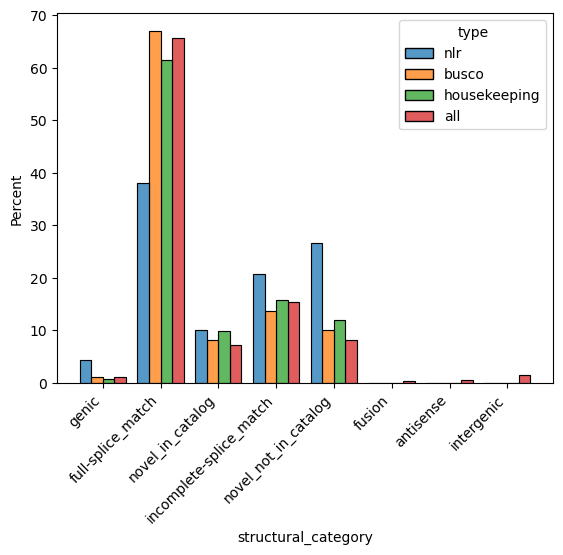

In [27]:
sns.histplot(acc_all, x="structural_category", hue = "type", multiple= "dodge", stat="percent", common_norm=False, shrink = 0.8)
plt.xticks(rotation=45, horizontalalignment='right')

## All at oncevalue_counts

In [28]:
### Liftoff

In [29]:
accessions= ['at6923','at6929','at7143','at8285','at9104','at9336','at9503','at9578','at9744','at9762','at9806','at9830','at9847','at9852','at9879','at9883','at9900','col0']


tama_liftoff_df = pd.DataFrame()
tama_subcat = pd.DataFrame()

for acc in accessions:
    # prepare sqanti output
    sqanti = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/{}_liftoff_sqanti/{}-tama-vs-liftoff_classification.txt".format(acc,acc), sep="\t")
    sub = sqanti[["isoform","exons","length","structural_category","associated_gene","associated_transcript","subcategory","ORF_seq"]]
    sub["gene"] = sub["isoform"].str.split(".").str[0]

    # prepare read support
    reads = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/{}.collapsed.tama.v2_read_support.txt".format(acc), sep="\t")
    r_sub = reads[["merge_trans_id","trans_read_count","gene_read_count"]]
    r_sub.columns = ["isoform", "isoform_reads", "gene_reads"]
    
    
    # add accession ID and merge all information
    merged_all = pd.merge(left=sub, right=r_sub, how='left', left_on='isoform', right_on='isoform')
    merged_all['accession'] = acc
    tama_liftoff_df = pd.concat([tama_liftoff_df, merged_all])
    
    # prepare the subcategory dataframe:
    idx=sub["structural_category"].value_counts().index
    cat_df = pd.DataFrame({"accession":[acc]})
    for cat in idx:
        cat_df[cat]=sub["structural_category"].value_counts()[cat]
    test=cat_df.set_index("accession").T[acc].sum()
    cat_df["sum"] = cat_df.set_index("accession").T[acc].sum()
    tama_subcat=pd.concat([tama_subcat, cat_df], ignore_index=True).fillna(0)


KeyboardInterrupt



In [32]:
tama_liftoff_df = tama_liftoff_df[["gene","isoform","accession","associated_gene","associated_transcript","exons","length","isoform_reads","gene_reads","structural_category","subcategory","ORF_seq"]]
tama_liftoff_df.columns = ["gene","isoform","accession","associated_gene","associated_transcript","exons","length","isoform_read_support","gene_read_support","structural_category","subcategory","Sqanti_ORF_seq"]
tama_liftoff_df.to_csv("./tama_liftoff_sqanti.tsv", sep="\t")

### Look at the total distribution over all genes

KeyboardInterrupt: 

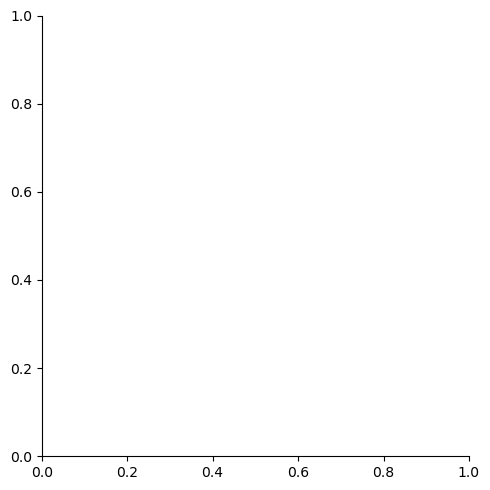

In [39]:
sns.displot(tama_liftoff_df, x="exons", hue = "accession", kind="kde",common_norm=False)

In [ ]:
sns.displot(tama_liftoff_df, x="length", hue = "accession", kind="kde",common_norm=False)

### Subset via genes nlr vs busco and house

In [ ]:
all_gene_ref = pd.merge(left=tama_liftoff_df, right=gene_type, how='left', left_on='associated_gene', right_on='ref_gene')
print(all_gene_ref["type"].value_counts())
all_gene_nlr = all_gene_ref.loc[all_gene_ref["type"] == "nlr"]
all_gene_busco = all_gene_ref.loc[all_gene_ref["type"] == "busco"]
all_gene_house = all_gene_ref.loc[all_gene_ref["type"] == "housekeeping"]
all_gene_all = pd.concat([all_gene_nlr,all_gene_busco,all_gene_house])

In [ ]:
sns.displot(all_gene_all, x="exons", hue = "type", kind="kde",common_norm=False)

In [ ]:
sns.displot(all_gene_all, x="length", hue = "type", kind="kde",common_norm=False)

### Include all genes as background

In [ ]:
tt = merged_all.copy()
tt["ref_isoform"] = "None"
tt["type"] = "all"
tt["ref_gene"] = "None"
tt.head()
all_acc_all = pd.concat([all_gene_all,tt], ignore_index=True)

In [ ]:
sns.displot(all_acc_all, x="exons", hue = "type", kind="kde",common_norm=False)

In [ ]:
sns.displot(all_acc_all, x="length", hue = "type", kind="kde",common_norm=False)

### Histogram of structral categories

In [ ]:
sns.histplot(all_acc_all, x="structural_category", hue = "type", multiple= "dodge", stat="percent", common_norm=False, shrink = 0.8)
plt.xticks(rotation=45, horizontalalignment='right')

In [ ]:
sns.histplot(all_acc_all, x="subcategory", hue = "type", multiple= "dodge", stat="percent", common_norm=False, shrink = 0.8)
plt.xticks(rotation=45, horizontalalignment='right')

### Iterate over subcategories and plot the accessions per category

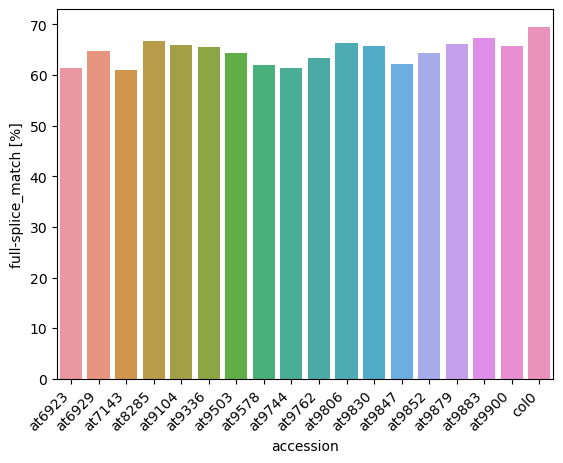

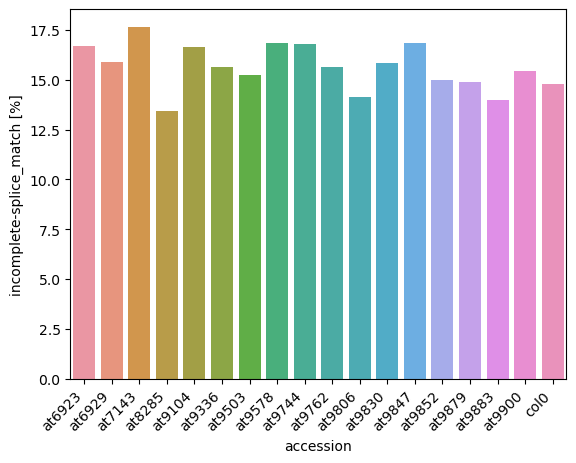

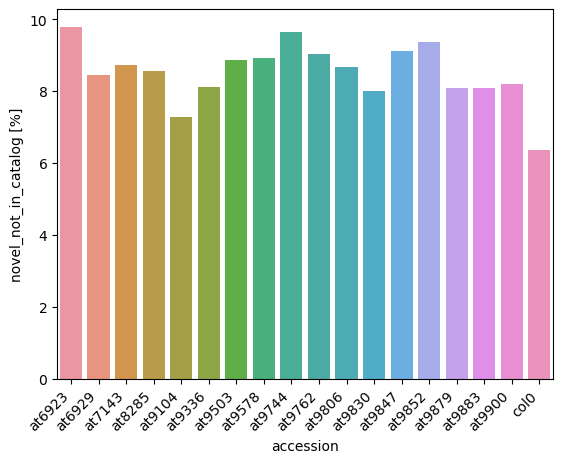

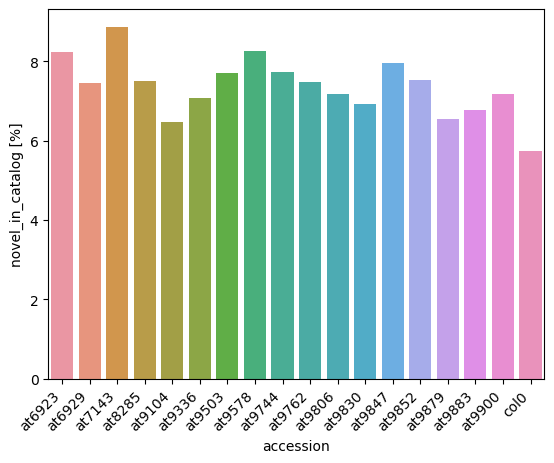

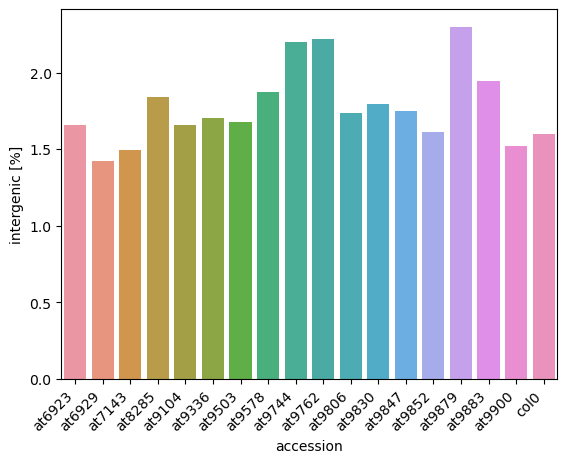

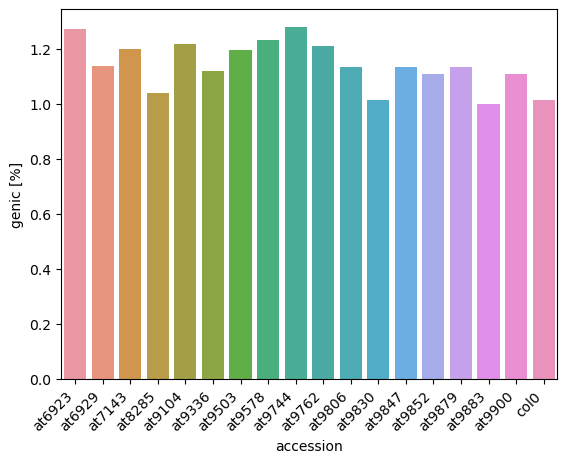

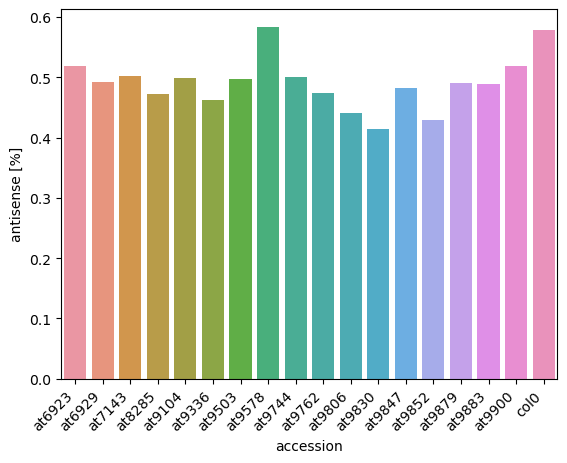

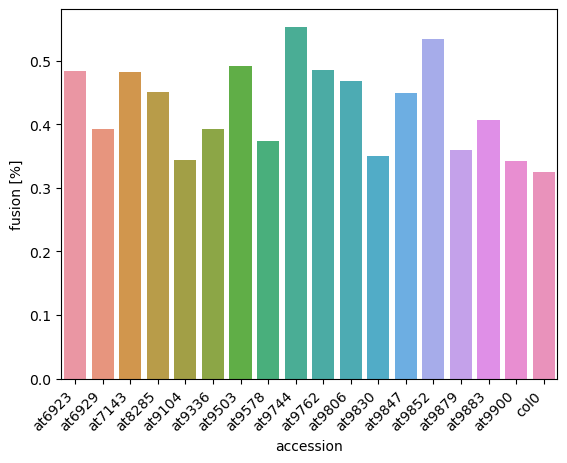

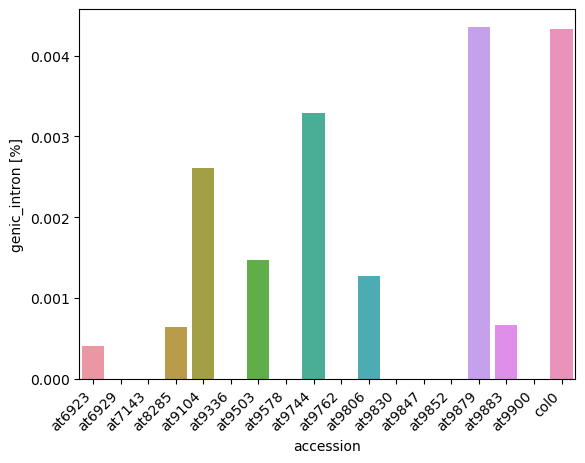

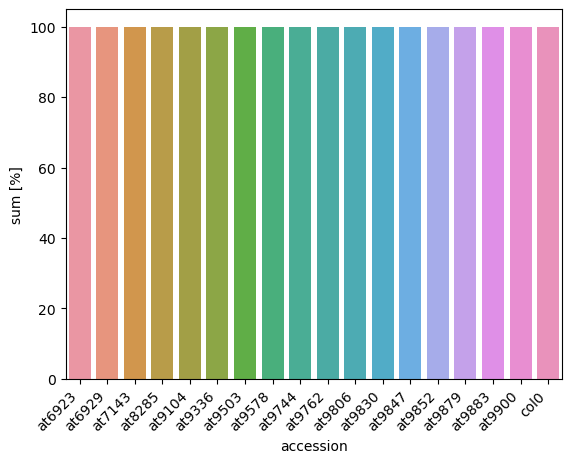

In [154]:
t = tama_subcat.copy()
for cat in t.set_index("accession").columns:
    t["proportion"]=t[cat]/t["sum"]*100
    #plt.figure()
    sns.barplot(data=t, x="accession", y="proportion")
    plt.xticks(rotation=45, horizontalalignment='right')
    plt.ylabel("{} [%]".format(cat))
    plt.show()

### Iterate over subcategories and plot the gene types (nlr, busco, house)(X=subcategory)

### augustus

In [33]:
accessions= ['at6923','at6929','at7143','at8285','at9104','at9336','at9503','at9578','at9744','at9762','at9806','at9830','at9847','at9852','at9879','at9883','at9900','col0']


tama_augustus_df = pd.DataFrame()

for acc in accessions:
    sqanti = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/{}_augustus_sqanti/{}-tama-vs-augustus_classification.txt".format(acc,acc), sep="\t")
    sub = sqanti[["isoform","exons","length","structural_category","associated_gene","associated_transcript","subcategory","ORF_seq"]]
    sub["gene"] = sub["isoform"].str.split(".").str[0]
    
    reads = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/{}.collapsed.tama.v2_read_support.txt".format(acc), sep="\t")
    r_sub = reads[["merge_trans_id","trans_read_count","gene_read_count"]]
    r_sub.columns = ["isoform", "isoform_reads", "gene_reads"]

    merged_all = pd.merge(left=sub, right=r_sub, how='left', left_on='isoform', right_on='isoform')
    merged_all['accession'] = acc
    
    tama_augustus_df = pd.concat([tama_augustus_df, merged_all])
print(tama_augustus_df)

/tmp/ipykernel_187333/3562157183.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sub["gene"] = sub["isoform"].str.split(".").str[0]
/tmp/ipykernel_187333/3562157183.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mRNA['isoform'] = mRNA['attributes'].str.split(";").str[0].str.split("=").str[1].str.split(".p").str[0]
/tmp/ipykernel_187333/3562157183.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

          isoform  exons  length      structural_category associated_gene  \
0            G1.1      6    1663        full-splice_match              g1   
1            G1.2      6    1588        full-splice_match              g1   
2           G10.1      3    1640        full-splice_match              g9   
3          G10.10      2    1175  incomplete-splice_match              g9   
4          G10.11      3    1473        full-splice_match              g9   
...           ...    ...     ...                      ...             ...   
161839  G16250.51      1     992               intergenic  novelGene_1545   
161840   G16250.6      1    2946        full-splice_match       ATMG01370   
161841   G16250.7      1    2847        full-splice_match       ATMG01370   
161842   G16250.8      1    2776        full-splice_match       ATMG01370   
161843   G16250.9      1    2764        full-splice_match       ATMG01370   

       associated_transcript           subcategory  \
0                    

In [34]:
tama_augustus_df = tama_augustus_df[["gene","isoform","accession","associated_gene","associated_transcript","exons","length","isoform_reads","gene_reads","structural_category","subcategory","ORF_seq"]]
tama_augustus_df.columns = ["gene","isoform","accession","associated_gene","associated_transcript","exons","length","isoform_read_support","gene_read_support","structural_category","subcategory","Sqanti_ORF_seq"]
tama_augustus_df.to_csv("./tama_augustus_sqanti.tsv", sep="\t")

# Subset by read read support of isoform > 1

In [35]:
iso2 = merged_all.copy()
iso2

,isoform,exons,length,structural_category,associated_gene,associated_transcript,subcategory,ORF_seq,gene,n_ORFS,isoform_reads,gene_reads,accession
0,G1.1,7,1080,novel_in_catalog,AT1G01020,novel,intron_retention,NaN,G1,1.0,1,2,col0
1,G1.2,9,819,incomplete-splice_match,AT1G01020,AT1G01020.1,5prime_fragment,MAASEHRCVGCGFRVKSLFIQYSPGNIRLMKCGNCKEVADEYIECE...,G1,1.0,1,2,col0
2,G10.1,1,1983,full-splice_match,AT1G01120,AT1G01120.1,mono-exon,MERTNSIEMDRERLTAEMAFRDSSSAVIRIRRRLPDLLTSVKLKYV...,G10,1.0,1,42,col0
3,G10.2,1,1772,full-splice_match,AT1G01120,AT1G01120.1,mono-exon,MERTNSIEMDRERLTAEMAFRDSSSAVIRIRRRLPDLLTSVKLKYV...,G10,1.0,1,42,col0
4,G10.3,1,1843,full-splice_match,AT1G01120,AT1G01120.1,mono-exon,MERTNSIEMDRERLTAEMAFRDSSSAVIRIRRRLPDLLTSVKLKYV...,G10,1.0,1,42,col0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
161839,G16250.51,1,992,intergenic,novelGene_1545,novel,mono-exon,NaN,G16250,NaN,1,77,col0
161840,G16250.6,1,2946,full-splice_match,ATMG01370,ATMG01370.1,mono-exon,NaN,G16250,NaN,1,77,col0
161841,G16250.7,1,2847,full-splice_match,ATMG01370,ATMG01370.1,mono-exon,NaN,G16250,NaN,1,77,col0
161842,G16250.8,1,2776,full-splice_match,ATMG01370,ATMG01370.1,mono-exon,NaN,G16250,NaN,1,77,col0


In [36]:
iso2[iso2["isoform_reads"]>1]

,isoform,exons,length,structural_category,associated_gene,associated_transcript,subcategory,ORF_seq,gene,n_ORFS,isoform_reads,gene_reads,accession
5,G10.4,1,1856,full-splice_match,AT1G01120,AT1G01120.1,mono-exon,MERTNSIEMDRERLTAEMAFRDSSSAVIRIRRRLPDLLTSVKLKYV...,G10,1.0,17,42,col0
6,G10.5,1,1839,full-splice_match,AT1G01120,AT1G01120.1,mono-exon,MERTNSIEMDRERLTAEMAFRDSSSAVIRIRRRLPDLLTSVKLKYV...,G10,1.0,22,42,col0
8,G100.10,8,1178,full-splice_match,AT1G02410,AT1G02410.1,reference_match,MSWSKACRGTRISSYLENLHRTSQYPRTILCSRYYTHGACKSNEHY...,G100,1.0,2,15,col0
30,G1000.7,1,1421,full-splice_match,AT1G15000,AT1G15000.1,mono-exon,MEQATTLFILLSTLLLAVSVESPQPPLFPDEALPTKSGYLPVKPAP...,G1000,1.0,2,17,col0
32,G1000.9,1,1467,full-splice_match,AT1G15000,AT1G15000.1,mono-exon,MEQATTLFILLSTLLLAVSVESPQPPLFPDEALPTKSGYLPVKPAP...,G1000,1.0,5,17,col0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
161813,G16250.28,1,2378,intergenic,novelGene_1523,novel,mono-exon,NaN,G16250,NaN,2,77,col0
161820,G16250.34,1,1934,intergenic,novelGene_1528,novel,mono-exon,NaN,G16250,NaN,4,77,col0
161829,G16250.42,1,1592,intergenic,novelGene_1536,novel,mono-exon,NaN,G16250,NaN,2,77,col0
161834,G16250.47,1,1386,intergenic,novelGene_1541,novel,mono-exon,NaN,G16250,NaN,2,77,col0


# Subset by read read support of gene > 1

In [37]:
gene2 = merged_all.copy()
gene2

,isoform,exons,length,structural_category,associated_gene,associated_transcript,subcategory,ORF_seq,gene,n_ORFS,isoform_reads,gene_reads,accession
0,G1.1,7,1080,novel_in_catalog,AT1G01020,novel,intron_retention,NaN,G1,1.0,1,2,col0
1,G1.2,9,819,incomplete-splice_match,AT1G01020,AT1G01020.1,5prime_fragment,MAASEHRCVGCGFRVKSLFIQYSPGNIRLMKCGNCKEVADEYIECE...,G1,1.0,1,2,col0
2,G10.1,1,1983,full-splice_match,AT1G01120,AT1G01120.1,mono-exon,MERTNSIEMDRERLTAEMAFRDSSSAVIRIRRRLPDLLTSVKLKYV...,G10,1.0,1,42,col0
3,G10.2,1,1772,full-splice_match,AT1G01120,AT1G01120.1,mono-exon,MERTNSIEMDRERLTAEMAFRDSSSAVIRIRRRLPDLLTSVKLKYV...,G10,1.0,1,42,col0
4,G10.3,1,1843,full-splice_match,AT1G01120,AT1G01120.1,mono-exon,MERTNSIEMDRERLTAEMAFRDSSSAVIRIRRRLPDLLTSVKLKYV...,G10,1.0,1,42,col0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
161839,G16250.51,1,992,intergenic,novelGene_1545,novel,mono-exon,NaN,G16250,NaN,1,77,col0
161840,G16250.6,1,2946,full-splice_match,ATMG01370,ATMG01370.1,mono-exon,NaN,G16250,NaN,1,77,col0
161841,G16250.7,1,2847,full-splice_match,ATMG01370,ATMG01370.1,mono-exon,NaN,G16250,NaN,1,77,col0
161842,G16250.8,1,2776,full-splice_match,ATMG01370,ATMG01370.1,mono-exon,NaN,G16250,NaN,1,77,col0


In [38]:
gene2[gene2["gene_reads"]==1]

,isoform,exons,length,structural_category,associated_gene,associated_transcript,subcategory,ORF_seq,gene,n_ORFS,isoform_reads,gene_reads,accession
77,G1007.1,5,504,full-splice_match,AT1G15120,AT1G15120.1,alternative_3end,NaN,G1007,NaN,1,1,col0
78,G1008.1,4,1206,full-splice_match,AT1G15125,AT1G15125.1,alternative_3end,MNGGDGASSYARNSSYQRGAIEAAEALLRNEINARLDITNHSFSSF...,G1008,1.0,1,1,col0
155,G1017.1,4,862,full-splice_match,AT1G15220,AT1G15220.2,alternative_3end,MEKTDEERKKAQMLDARARNISHNVRCTECGSQSIEDSQADIAILL...,G1017,1.0,1,1,col0
170,G1020.1,4,519,full-splice_match,AT1G15250,AT1G15250.1,reference_match,NaN,G1020,NaN,1,1,col0
176,G1022.1,4,454,full-splice_match,AT1G15270,AT1G15270.1,reference_match,NaN,G1022,NaN,1,1,col0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
161776,G16241.1,1,1697,full-splice_match,ATMG01170,ATMG01170.1,mono-exon,NaN,G16241,1.0,1,1,col0
161783,G16243.1,1,479,antisense,novelGene_ATMG01260_AS,novel,mono-exon,NaN,G16243,NaN,1,1,col0
161786,G16245.1,1,2062,antisense,novelGene_ATMG01280_AS_novelGene_ATMG01275_AS,novel,mono-exon,NaN,G16245,2.0,1,1,col0
161791,G16248.1,1,2343,intergenic,novelGene_1514,novel,mono-exon,MLVLSHKDYGMLVLSHKDYAEPSPEKDYDLGIPAAAATPFEVGRSL...,G16248,1.0,1,1,col0


### Generate list of subdataframes (ORF analysis)

In [30]:
genes = list(sub.groupby("gene"))

gene2ORF = {}
for i in genes:
    gene2ORF[i[0]]={}
    orfs = i[1]["ORF_seq"].value_counts().index.tolist()
    for orf in orfs:
        gene2ORF[i[0]][orf] = i[1].loc[i[1]["ORF_seq"] == orf]["isoform"].tolist()

### Extract n ORFs and n Isoforms

In [31]:
ORF2iso = pd.DataFrame()
for gene in tqdm(gene2ORF.keys()):
    # get the isoforms per ORF + calculate the number of isoforms per ORF
    isoforms=[]
    n_isoforms=[]
    for orf in gene2ORF[gene].keys():
        isoforms.append(gene2ORF[gene][orf])
        n_isoforms.append(len(gene2ORF[gene][orf]))
    # get read support and sqanti subcategory per isoform
    read_support=[]
    subcategories=[]
    for l in isoforms:
        read_supp_list=[]
        category_list = []
        for iso in l:
            # read support
            rs=merged_all.loc[merged_all["isoform"] == iso]["isoform_reads"]
            read_supp_list.append(int(rs.to_string().split("    ")[1]))
            # subcategory
            subcat = merged_all.loc[merged_all["isoform"] == iso]["subcategory"]
            category_list.append(subcat.to_string().split("    ")[1])
        read_support.append(read_supp_list)
        subcategories.append(category_list)
    gene={"Gene":gene,
          "n ORFs":len(gene2ORF[gene]),
          "n Isoforms": sum(n_isoforms),
          "Sqanti ORFs":list(gene2ORF[gene].keys()),
          "Isoforms":isoforms,
          "n_Isoforms_ORF":[len(x) for x in isoforms],
          "Subcategories":subcategories,
          "Read_Support":read_support,
          "Read_Support_ORF":[sum(x) for x in read_support]}
    ORF2iso=pd.concat([ORF2iso, pd.DataFrame([gene])])
#ORF2iso.head()
## Idea: What if Sqanti and Transdecoder overlap and if so, use the agreement for later isoform assignments?
## Idea2: 

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 16754/16754 [1:42:56<00:00,  2.71it/s]


In [32]:
ORF2iso.to_csv("Tama_ORF_sqanti_analysis.tsv", sep="\t")
ORF2iso.to_pickle("Tama_ORF_sqanti_analysis.pkl")

In [22]:
def read(file_name):
    try:
        fasta = open(file_name, 'r')
        fasta_pairs = {}
        header = ''
        # check every line for a new header
        # if so, set as key and set non header lines as value
        for line in fasta:
            if line[0] == '>':
                header = line.strip('\n')
                fasta_pairs[header] = ''
            else:
                fasta_pairs[header] += line.strip('\n')
        # return dict of fasta entries
        return fasta_pairs
    except IOError:
        print("File \"{}\" could not be opened.".format(file_name))

In [5]:
fasta=read("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/at9900_transdecoder/at9900_transcripts.fasta.transdecoder.genome.sorted.protein.fasta")

In [6]:
trans_df=pd.DataFrame()

for key in tqdm(fasta.keys()):
    gene = key.split(".")[0].replace(">","")
    iso = key.split(" ")[0].replace(">","").rsplit('.', 1)[0]
    p = key.split(" ")[0].replace(">","").rsplit('.', 1)[1]    
    row={"Gene":gene,
        "isoform":iso,
        "ORF_variant":p,
        "Transdecoder ORF":fasta[key].replace("*","")}
    trans_df=pd.concat([trans_df,pd.DataFrame([row])])

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 208084/208084 [2:05:44<00:00, 27.58it/s]


In [7]:
trans_genes = list(trans_df.groupby("Gene"))

In [8]:
gene2ORF_trans = {}
for i in trans_genes:
    gene2ORF_trans[i[0]]={}
    orfs = i[1]["Transdecoder ORF"].value_counts().index.tolist()
    for orf in orfs:
        gene2ORF_trans[i[0]][orf] = i[1].loc[i[1]["Transdecoder ORF"] == orf]["isoform"].tolist()

In [15]:
ORF_trans=pd.DataFrame()

df_add=pd.DataFrame()
for gene in tqdm(gene2ORF_trans.keys()):
    # get the isoforms per ORF + calculate the number of isoforms per ORF
    isoforms=[]
    n_isoforms=[]
    for orf in gene2ORF_trans[gene].keys():
        isoforms.append(gene2ORF_trans[gene][orf])
        n_isoforms.append(len(gene2ORF_trans[gene][orf]))
    # get read support and sqanti subcategory per isoform
    read_support=[]
    subcategories=[]
    for l in isoforms:
        read_supp_list=[]
        category_list = []
        for iso in l:
            # read support
            rs=merged_all.loc[merged_all["isoform"] == iso]["isoform_reads"]
            read_supp_list.append(int(rs.to_string().split("    ")[1]))
            # subcategory
            subcat = merged_all.loc[merged_all["isoform"] == iso]["subcategory"]
            category_list.append(subcat.to_string().split("    ")[1])
        read_support.append(read_supp_list)
        subcategories.append(category_list)
    gene={"Gene":gene,
          "n ORFs":len(gene2ORF_trans[gene]),
          "n Isoforms": sum(n_isoforms),
          "Sqanti ORFs":list(gene2ORF_trans[gene].keys()),
          "Isoforms":isoforms,
          "n_Isoforms_ORF":[len(x) for x in isoforms],
          "Subcategories":subcategories,
          "Read_Support":read_support,
          "Read_Support_ORF":[sum(x) for x in read_support]}
    ORF_trans=pd.concat([ORF_trans, pd.DataFrame([gene])])

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 16096/16096 [1:54:49<00:00,  2.34it/s]


In [16]:
ORF_trans.to_csv("Tama_ORF_transdecoder_analysis.tsv", sep="\t")

In [18]:
ORF_trans.to_pickle("Tama_ORF_transdecoder_analysis.pkl")

In [38]:
test= sub.set_index("gene").sort_index().stack()

gene                        
G1     isoform                                                               G1.1
       exons                                                                    6
       structural_category                                      full-splice_match
       associated_gene                                                  AT1G01010
       associated_transcript                                          AT1G01010.1
                                                      ...                        
G9999  exons                                                                    7
       structural_category                                      full-splice_match
       associated_gene                                                  AT3G60210
       associated_transcript                                          AT3G60210.1
       ORF_seq                  MASSFITVPKPFLSFPIKTNAPTLPQQTLLGIRRNSFRINAVSTKW...
Length: 1178291, dtype: object


In [11]:
orf=pd.read_pickle("sqanti/at9900_tama_liftoff_sqanti_orf.pkl")

In [12]:
orf.head()

,Gene,n ORFs,n Isoforms,Sqanti ORFs,Isoforms,n_Isoforms_ORF,Subcategories,Read_Support,Read_Support_ORF
0,G1,1,2,[MEDQVGFGFRPNDEELVGHYLRNKIEGNTSRDVEVAISEVNICSY...,"[[G1.1, G1.2]]",[2],"[[alternative_3end, reference_match]]","[[1, 1]]",[2]
0,G10,2,2,[MGKKNGSSSWLTAVKRAFRSPTKKDHSNDVEEDEEKKREKRRWFR...,"[[G10.1], [G10.2]]","[1, 1]","[[alternative_5end], [at_least_one_novel_splic...","[[1], [1]]","[1, 1]"
0,G100,7,32,[MGSLVREWVGFQQFPAATQEKLIEFFGKLKQKDMNSMTVLVLGKG...,"[[G100.1, G100.10, G100.11, G100.13, G100.16, ...","[18, 8, 2, 1, 1, 1, 1]","[[alternative_3end, reference_match, intron_re...","[[1, 35, 1, 2, 1, 1, 5, 1, 1, 1, 3, 1, 2, 1, 1...","[77, 10, 2, 1, 1, 1, 1]"
0,G1000,1,1,[MSELSYSLPSWDLHNLGSLFNQNFNLDAWGLIDESPENIFCSPEM...,[[G1000.1]],[1],[[alternative_3end]],[[1]],[1]
0,G10000,2,2,[MESLINPSHGGGNYDSHSSSLDSLKPSVLVIILILLMTLLISVSI...,"[[G10000.1], [G10000.2]]","[1, 1]","[[mono-exon], [mono-exon]]","[[1], [1]]","[1, 1]"


In [9]:
orf_trans=pd.read_pickle("orf/at9900_tama_liftoff_transdecoder_orf.pkl")

In [10]:
orf_trans.head()

,Gene,n ORFs,n Isoforms,Sqanti ORFs,Isoforms,n_Isoforms_ORF,Subcategories,Read_Support,Read_Support_ORF
0,G1,1,2,[MEDQVGFGFRPNDEELVGHYLRNKIEGNTSRDVEVAISEVNICSY...,"[[G1.1, G1.2]]",[2],"[[alternative_3end, reference_match]]","[[1, 1]]",[2]
0,G10,2,2,[MGKKNGSSSWLTAVKRAFRSPTKKDHSNDVEEDEEKKREKRRWFR...,"[[G10.1], [G10.2]]","[1, 1]","[[alternative_5end], [at_least_one_novel_splic...","[[1], [1]]","[1, 1]"
0,G100,12,35,[MGSLVREWVGFQQFPAATQEKLIEFFGKLKQKDMNSMTVLVLGKG...,"[[G100.1, G100.2, G100.5, G100.6, G100.9, G100...","[17, 8, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]","[[alternative_3end, reference_match, reference...","[[1, 1, 1, 17, 2, 35, 2, 1, 1, 5, 1, 1, 3, 1, ...","[76, 10, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]"
0,G1000,1,1,[NTFTVNPQIIKKNMSELSYSLPSWDLHNLGSLFNQNFNLDAWGLI...,[[G1000.1]],[1],[[alternative_3end]],[[1]],[1]
0,G10000,2,2,[SSSSLSVSLCASSLLSSMESLINPSHGGGNYDSHSSSLDSLKPSV...,"[[G10000.1], [G10000.2]]","[1, 1]","[[mono-exon], [mono-exon]]","[[1], [1]]","[1, 1]"
